In [2]:
#Вариант 5
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

order_files = [
    "orders_2024_01.csv",
    "orders_2024_02.csv",
    "orders_2024_03.csv"
]

df_orders = pd.concat(
    [pd.read_csv(file, parse_dates=["order_datetime"]) for file in order_files],
    ignore_index=True
)

print("Таблица заказов:")
print(df_orders.head())

order_files = [
    "orders_2024_01.csv",
    "orders_2024_02.csv",
    "orders_2024_03.csv"
]

df_orders = pd.concat(
    [pd.read_csv(file, parse_dates=["order_datetime"]) for file in order_files],
    ignore_index=True
)

print("Таблица заказов:")
print(df_orders.head())



df_events_records = pd.read_json(
    "events_records.json",
    orient="columns"
).T

df_events_records.columns = [
    "event_id", "user_id", "event_time", "event_type", "page"
]

df_events_records["event_id"] = df_events_records["event_id"].astype(int)
df_events_records["user_id"] = df_events_records["user_id"].astype(int)
df_events_records["event_time"] = pd.to_datetime(
    df_events_records["event_time"]
)

df_events_lines = pd.read_json("events_lines.json", lines=True)

df_events = pd.concat(
    [df_events_records, df_events_lines],
    ignore_index=True
)

df_events["event_time"] = pd.to_datetime(df_events["event_time"])

print("\nТаблица событий:")
print(df_events.head())

Таблица заказов:
   order_id  user_id      order_datetime  product_id     price  quantity  \
0         1     1044 2024-01-03 18:39:26          26  14038.15         1   
1         2     1079 2024-01-03 17:45:43          16   9172.60         1   
2         3     1041 2024-01-06 22:46:38          25   9035.26         2   
3         4     1083 2024-01-08 21:03:51           9  15234.33         3   
4         5     1068 2024-01-03 23:26:53          24   4134.38         2   

     status  
0  refunded  
1      paid  
2      paid  
3      paid  
4      paid  
Таблица заказов:
   order_id  user_id      order_datetime  product_id     price  quantity  \
0         1     1044 2024-01-03 18:39:26          26  14038.15         1   
1         2     1079 2024-01-03 17:45:43          16   9172.60         1   
2         3     1041 2024-01-06 22:46:38          25   9035.26         2   
3         4     1083 2024-01-08 21:03:51           9  15234.33         3   
4         5     1068 2024-01-03 23:26:53     

In [3]:
orders_activity = df_orders.groupby("user_id").agg(
    first_order=("order_datetime", "min"),
    last_order=("order_datetime", "max")
)

events_activity = df_events.groupby("user_id").agg(
    first_event=("event_time", "min"),
    last_event=("event_time", "max")
)

user_features = orders_activity.join(
    events_activity,
    how="outer"
)

date_columns = [
    "first_order", "last_order",
    "first_event", "last_event"
]

for column in date_columns:
    user_features[column] = pd.to_datetime(user_features[column])

user_features["first_activity"] = user_features[
    ["first_order", "first_event"]
].min(axis=1)

user_features["last_activity"] = user_features[
    ["last_order", "last_event"]
].max(axis=1)

user_features["lifetime_days"] = (
    user_features["last_activity"] -
    user_features["first_activity"]
).dt.days

print("\nЗадание 1. Длина жизни клиентов в днях:")
print(
    user_features[
        ["first_activity", "last_activity", "lifetime_days"]
    ].head()
)


Задание 1. Длина жизни клиентов в днях:
             first_activity       last_activity  lifetime_days
user_id                                                       
1001    2024-01-01 06:25:31 2024-03-31 22:29:02             90
1002    2024-01-02 12:57:34 2024-03-31 21:24:08             89
1003    2024-01-02 02:02:44 2024-03-31 19:36:26             89
1004    2024-01-01 00:19:34 2024-03-31 20:01:40             90
1005    2024-01-01 01:11:51 2024-03-31 18:16:10             90


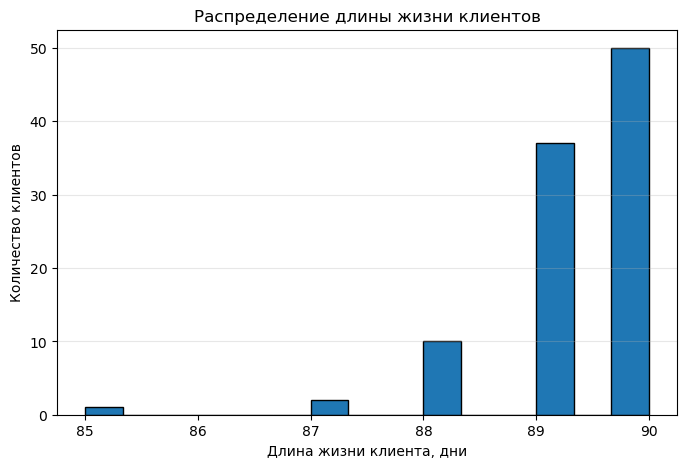


Задание 2. Статистика длины жизни клиентов:
count    100.000000
mean      89.320000
std        0.863163
min       85.000000
25%       89.000000
50%       89.500000
75%       90.000000
max       90.000000
Name: lifetime_days, dtype: float64


In [4]:
plt.figure(figsize=(8, 5))
plt.hist(
    user_features["lifetime_days"].dropna(),
    bins=15,
    edgecolor="black"
)

plt.title("Распределение длины жизни клиентов")
plt.xlabel("Длина жизни клиента, дни")
plt.ylabel("Количество клиентов")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("\nЗадание 2. Статистика длины жизни клиентов:")
print(user_features["lifetime_days"].describe())


In [5]:
user_features["life_segment"] = pd.cut(
    user_features["lifetime_days"],
    bins=[-1, 30, 60, float("inf")],
    labels=["Новый", "Активный", "Старый"]
)

print("\nЗадание 3. Сегменты жизни клиентов:")
print(
    user_features[
        ["lifetime_days", "life_segment"]
    ].head()
)

print("\nКоличество клиентов в каждом сегменте:")
print(user_features["life_segment"].value_counts())



Задание 3. Сегменты жизни клиентов:
         lifetime_days life_segment
user_id                            
1001                90       Старый
1002                89       Старый
1003                89       Старый
1004                90       Старый
1005                90       Старый

Количество клиентов в каждом сегменте:
life_segment
Старый      100
Новый         0
Активный      0
Name: count, dtype: int64
